# 04 · Stochastic Gradient Descent and ADAM

**Thesis reference:** Chapter 1, Section 1.5 (*Stochastic Gradient Descent and ADAM*): 1.5.1 loss functions, 1.5.2 one sample per step, 1.5.3 fast convergence at the start, 1.5.7 weight averaging, 1.5.8 adaptive methods.

Training a model means minimizing an average loss over $N$ samples,
$$L(w) = \frac1N \sum_{i=1}^{N} \ell_i(w).$$
Full gradient descent touches all $N$ samples per step. **SGD** uses one sample, or a small mini-batch $B$:
$$w_{k+1} = w_k - s_k\, \frac{1}{|B|}\sum_{i\in B} \nabla \ell_i(w_k).$$

This notebook implements every optimizer **from scratch in NumPy** and compares them on a real dataset: logistic regression on the Wisconsin breast-cancer data (569 patients, 30 features).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.optimize import minimize
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
X, y = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
scaler = StandardScaler().fit(X_tr)
add_bias = lambda A: np.c_[np.ones(len(A)), A]
X_tr, X_te = add_bias(scaler.transform(X_tr)), add_bias(scaler.transform(X_te))
N, d = X_tr.shape
print(f"train: {N} samples, test: {len(X_te)} samples, {d - 1} features + bias")

train: 426 samples, test: 143 samples, 30 features + bias


## Loss function: L2-regularized logistic (cross-entropy) loss
$$L(w) = \frac1N\sum_i \Big[\log\big(1+e^{x_i^Tw}\big) - y_i\,x_i^Tw\Big] + \frac{\lambda}{2}\|w_{1:}\|^2, \qquad
\nabla L(w) = \frac1N X^T\big(\sigma(Xw) - y\big) + \lambda\, w_{1:}.$$

In [3]:
lam = 1e-3
sigmoid = lambda z: 1 / (1 + np.exp(-z))

def loss(w, X=X_tr, y=y_tr):
    z = X @ w
    return np.mean(np.logaddexp(0, z) - y * z) + 0.5 * lam * w[1:] @ w[1:]

def grad(w, X=X_tr, y=y_tr):
    g = X.T @ (sigmoid(X @ w) - y) / len(y)
    g[1:] += lam * w[1:]
    return g

accuracy = lambda w, X, y: np.mean((X @ w > 0) == y)

# reference optimum from a high-accuracy quasi-Newton solver
ref = minimize(loss, np.zeros(d), jac=grad, method="L-BFGS-B", options={"gtol": 1e-12, "maxiter": 10_000})
L_star = ref.fun
print(f"L* = {L_star:.6f}, reference test accuracy = {accuracy(ref.x, X_te, y_te):.3f}")

L* = 0.052328, reference test accuracy = 0.958


## The optimizers

All runs use the same budget of **60 epochs**, where one epoch is one pass over the training data.
* **GD:** one full-gradient step per epoch.
* **SGD:** one sample per step, $N$ steps per epoch.
* **SGD + momentum:** mini-batch 16, $v \leftarrow \beta v + g$, $w \leftarrow w - s v$.
* **ADAM:** mini-batch 16, with running averages of $g$ and $g^2$ and bias correction (Kingma & Ba, 2015):
$$m \leftarrow \beta_1 m + (1-\beta_1)g,\quad v \leftarrow \beta_2 v + (1-\beta_2)g^2,\quad
w \leftarrow w - s\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}.$$

In [4]:
def run(optimizer, epochs=60, batch=1, lr=0.01, seed=0, **kw):
    rng = np.random.default_rng(seed)
    w = np.zeros(d)
    state = {}
    history = [loss(w)]
    for _ in range(epochs):
        if optimizer == "gd":
            w = w - lr * grad(w)
        else:
            idx = rng.permutation(N)
            for start in range(0, N, batch):
                b = idx[start:start + batch]
                g = grad(w, X_tr[b], y_tr[b])
                w = step(optimizer, w, g, lr, state, **kw)
        history.append(loss(w))
    return w, np.array(history)

def step(optimizer, w, g, lr, state, beta=0.9, beta1=0.9, beta2=0.999, eps=1e-8):
    if optimizer == "sgd":
        return w - lr * g
    if optimizer == "momentum":
        state["v"] = beta * state.get("v", 0) + g
        return w - lr * state["v"]
    if optimizer == "adam":
        t = state["t"] = state.get("t", 0) + 1
        state["m"] = beta1 * state.get("m", 0) + (1 - beta1) * g
        state["v"] = beta2 * state.get("v", 0) + (1 - beta2) * g * g
        m_hat = state["m"] / (1 - beta1**t)
        v_hat = state["v"] / (1 - beta2**t)
        return w - lr * m_hat / (np.sqrt(v_hat) + eps)
    raise ValueError(optimizer)

configs = {
    "GD (full batch, lr=0.5)":          dict(optimizer="gd", lr=0.5),
    "SGD (batch 1, lr=0.01)":           dict(optimizer="sgd", batch=1, lr=0.01),
    "SGD + momentum (batch 16, lr=0.05)": dict(optimizer="momentum", batch=16, lr=0.05, beta=0.9),
    "ADAM (batch 16, lr=0.01)":         dict(optimizer="adam", batch=16, lr=0.01),
}
results = {name: run(**cfg) for name, cfg in configs.items()}

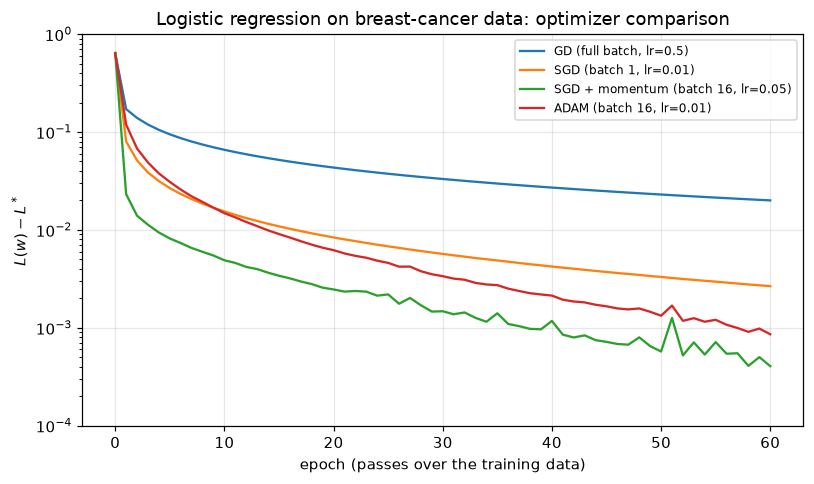

optimizer                               final L - L*  test acc
GD (full batch, lr=0.5)                     2.00e-02     0.965
SGD (batch 1, lr=0.01)                      2.66e-03     0.965
SGD + momentum (batch 16, lr=0.05)          4.05e-04     0.958
ADAM (batch 16, lr=0.01)                    8.58e-04     0.965


In [5]:
plt.figure(figsize=(7.5, 4.5))
for name, (w, hist) in results.items():
    plt.semilogy(hist - L_star + 1e-16, label=name)
plt.xlabel("epoch (passes over the training data)")
plt.ylabel(r"$L(w) - L^*$")
plt.title("Logistic regression on breast-cancer data: optimizer comparison")
plt.ylim(1e-4, 1)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "04_sgd_adam_comparison.png", bbox_inches="tight")
plt.show()

print(f"{'optimizer':38s} {'final L - L*':>13s} {'test acc':>9s}")
for name, (w, hist) in results.items():
    print(f"{name:38s} {hist[-1] - L_star:13.2e} {accuracy(w, X_te, y_te):9.3f}")

**Reading the plot.** Per pass over the data, the stochastic methods make fast progress at the start (Section 1.5.3) because they take $N$ (or $N/16$) cheap steps instead of one expensive step. Full-batch GD takes a single step per epoch and is far behind.
Plain SGD then slows down. With a constant learning rate its iterate never settles, because the gradient of a single sample is not zero at the optimum (see the averaging experiment below).
Momentum and ADAM reach a lower loss in the same budget, and the small wiggles in their curves are the mini-batch noise.

## Weight averaging inside SGD (Section 1.5.7)

With a constant step, the SGD iterate $w_k$ keeps bouncing around $w^*$.
The **average** of the iterates, $\bar w_k = \frac{1}{k-k_0}\sum_{j>k_0} w_j$ (Polyak–Ruppert averaging), cancels much of that noise.
We demonstrate this on least squares, where $w^*$ is known exactly.

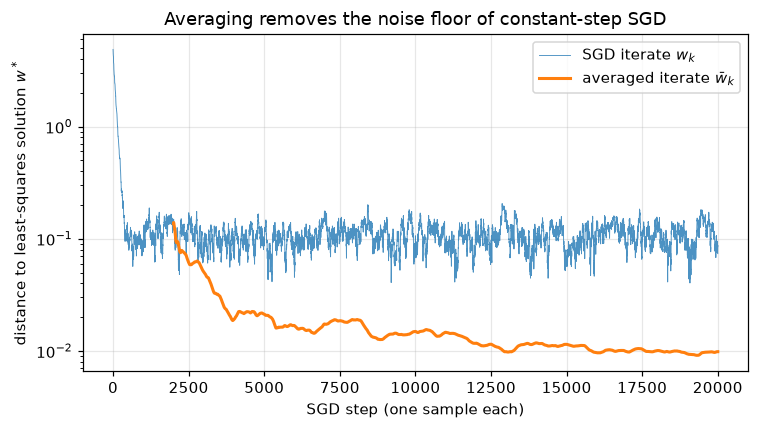

final distance: iterate 0.0738, averaged 0.0099


In [6]:
rng = np.random.default_rng(3)
n_ls, d_ls = 2000, 10
A = rng.standard_normal((n_ls, d_ls))
w_true = rng.standard_normal(d_ls)
b_ls = A @ w_true + 0.5 * rng.standard_normal(n_ls)
w_ls = np.linalg.lstsq(A, b_ls, rcond=None)[0]

w = np.zeros(d_ls)
avg = np.zeros(d_ls)
lr, burn_in = 0.01, n_ls
dist_iter, dist_avg = [], []
for k in range(10 * n_ls):
    i = rng.integers(n_ls)
    w -= lr * (A[i] @ w - b_ls[i]) * A[i]
    if k >= burn_in:
        avg += (w - avg) / (k - burn_in + 1)
    dist_iter.append(np.linalg.norm(w - w_ls))
    dist_avg.append(np.linalg.norm(avg - w_ls) if k >= burn_in else np.nan)

plt.figure(figsize=(7, 4))
plt.semilogy(dist_iter, lw=0.6, alpha=0.8, label="SGD iterate $w_k$")
plt.semilogy(dist_avg, lw=2, label=r"averaged iterate $\bar w_k$")
plt.xlabel("SGD step (one sample each)")
plt.ylabel(r"distance to least-squares solution $w^*$")
plt.title("Averaging removes the noise floor of constant-step SGD")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "04_sgd_averaging.png", bbox_inches="tight")
plt.show()
print(f"final distance: iterate {dist_iter[-1]:.4f}, averaged {dist_avg[-1]:.4f}")

### Takeaways
* SGD trades exact gradients for many cheap noisy steps. It wins early, but with a constant step size the iterate keeps fluctuating around the optimum.
* Momentum smooths the noisy directions. ADAM also rescales every coordinate by its own gradient history, which makes it robust to badly scaled features and is why it is the default optimizer for deep networks (notebook 07).
* Averaging the iterates, or decaying the learning rate, removes the noise floor.